# 06 — Feature Selection
**Member 6.** Keep a *subset of the original measurements*, rather than transformed
components, and test whether classifiers keep their performance.

Three selectors, each asked for **k = 5, 10, 15** features (all 30 as reference):

| Method | Type | How it ranks features |
|---|---|---|
| `SelectKBest(mutual_info_classif)` | filter | univariate mutual information with the label |
| `RFE(LogisticRegression)` | wrapper | repeatedly fits an L2 logistic regression and drops the feature with the smallest \|coefficient\| |
| L1 path (`L1PathSelector`, `src/feature_selectors.py`) | embedded | the first *k* features to get a non-zero weight as L1 regularisation is relaxed |

The classifiers (LR, KNN, SVM, Gaussian NB) are the same as in notebook 05 for a direct
PCA-vs-selection comparison, and they reuse the hyper-parameters tuned by Members 2–3.
Every selector sits inside the `Pipeline`, so it is re-fitted on each CV training fold
and selection never sees the validation fold. The test set is not used here.

In [1]:
import sys
sys.path.insert(0, "../src")
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from common import *
from models import build_pipeline, display_name
from feature_selectors import L1PathSelector, make_selector, METHODS, METHOD_NAMES

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160, "display.max_columns", 40)
X_train, X_test, y_train, y_test = get_split()
del X_test, y_test
PARAMS = load_best_params()
CLASSIFIERS = ["logreg", "knn", "svm", "gnb"]

## 1. Which features does each method pick? (full training set)

In [2]:
Z = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=FEATURE_NAMES, index=X_train.index)
rankings = {}
mi = pd.Series(mutual_info_classif(Z, y_train, random_state=RANDOM_STATE), index=FEATURE_NAMES)
rankings["MI"] = mi.rank(ascending=False, method="first")
rfe_full = RFE(LogisticRegression(solver="liblinear", max_iter=5000, random_state=RANDOM_STATE),
               n_features_to_select=1).fit(Z, y_train)
rankings["RFE"] = pd.Series(rfe_full.ranking_, index=FEATURE_NAMES).astype(float)
# L1 path: order in which features enter the model as C grows
enter = {}
for C in np.logspace(-3, 3, 121):
    coef = LogisticRegression(l1_ratio=1, solver="liblinear", C=C, max_iter=5000).fit(Z, y_train).coef_[0]
    for f, c in zip(FEATURE_NAMES, coef):
        if c != 0 and f not in enter:
            enter[f] = C
rank_l1 = pd.Series({f: enter.get(f, np.inf) for f in FEATURE_NAMES}).rank(method="first")
rankings["L1"] = rank_l1
rank_df = pd.DataFrame(rankings).rename(columns=METHOD_NAMES).astype(int)
rank_df["mean_rank"] = rank_df.mean(axis=1)
rank_df = rank_df.sort_values("mean_rank")
rank_df.to_csv(RESULTS_DIR / "feature_rankings.csv")
rank_df

,SelectKBest (MI),RFE (LR),L1 path,mean_rank
radius_worst,1,3,3,2.333333
concave_points_worst,5,2,2,3.000000
perimeter_worst,2,7,1,3.333333
concave_points_mean,4,6,4,4.666667
area_worst,3,1,11,5.000000
radius_se,13,4,8,8.333333
texture_worst,16,5,5,8.666667
concavity_worst,11,9,9,9.666667
symmetry_worst,18,14,6,12.666667
area_se,10,8,21,13.000000


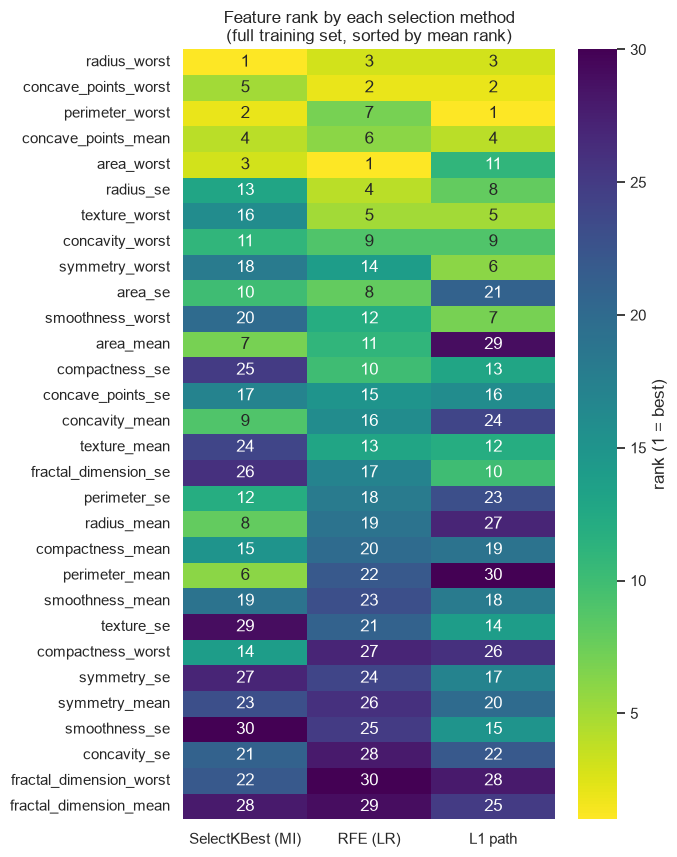

In [3]:
fig, ax = plt.subplots(figsize=(6, 10))
sns.heatmap(rank_df.drop(columns="mean_rank"), annot=True, fmt="d", cmap="viridis_r", cbar_kws={"label": "rank (1 = best)"}, ax=ax)
ax.set_title("Feature rank by each selection method\n(full training set, sorted by mean rank)")
savefig(fig, "06_feature_rank_heatmap"); plt.show()

In [4]:
for k in [5, 10, 15]:
    sets = {m: set(rank_df.index[rank_df[METHOD_NAMES[m]] <= k]) for m in METHODS}
    common_all = set.intersection(*sets.values())
    print(f"k={k:2d}  selected by all three: {len(common_all)}  -> {sorted(common_all)}")
    for m in METHODS:
        print(f"        {METHOD_NAMES[m]:17s}: {sorted(sets[m])}")

k= 5  selected by all three: 2  -> ['concave_points_worst', 'radius_worst']
        SelectKBest (MI) : ['area_worst', 'concave_points_mean', 'concave_points_worst', 'perimeter_worst', 'radius_worst']
        RFE (LR)         : ['area_worst', 'concave_points_worst', 'radius_se', 'radius_worst', 'texture_worst']
        L1 path          : ['concave_points_mean', 'concave_points_worst', 'perimeter_worst', 'radius_worst', 'texture_worst']
k=10  selected by all three: 4  -> ['concave_points_mean', 'concave_points_worst', 'perimeter_worst', 'radius_worst']
        SelectKBest (MI) : ['area_mean', 'area_se', 'area_worst', 'concave_points_mean', 'concave_points_worst', 'concavity_mean', 'perimeter_mean', 'perimeter_worst', 'radius_mean', 'radius_worst']
        RFE (LR)         : ['area_se', 'area_worst', 'compactness_se', 'concave_points_mean', 'concave_points_worst', 'concavity_worst', 'perimeter_worst', 'radius_se', 'radius_worst', 'texture_worst']
        L1 path          : ['concave_point

**The methods disagree in an informative way.**
* **Mutual information** is univariate: it ranks every feature on its own, so its top
  10 is crowded with near-duplicates (radius / perimeter / area in both `_mean` and
  `_worst` form, plus concave points). Each one is individually strong, but together they
  carry largely the same information.
* **RFE** and the **L1 path** are multivariate: once one size feature is in, its
  duplicates add little, so they prefer *complementary* features such as texture,
  smoothness, symmetry and `_se` measurements.
* At k = 10 all three methods agree on four features: `radius_worst`,
  `perimeter_worst`, `concave_points_worst` and `concave_points_mean`. These are the
  size and concavity of the most abnormal nuclei. RFE and the L1 path also both add
  `texture_worst` and `radius_se`.

## 2. Main experiment: k = 5, 10, 15 vs all 30 features

In [5]:
rows = []
for key in CLASSIFIERS:
    rows.append(cv_evaluate(build_pipeline(key, PARAMS[key]), X_train, y_train, name=display_name(key), key=key,
                            method="none", setting="all 30", n_features=30))
    for method in METHODS:
        for k in [5, 10, 15]:
            pipe = build_pipeline(key, PARAMS[key], reducer=make_selector(method, k))
            rows.append(cv_evaluate(pipe, X_train, y_train, name=display_name(key), key=key,
                                    method=method, setting=f"{METHOD_NAMES[method]} k={k}", n_features=k))
fs_df = pd.DataFrame(rows)
save_rows(rows, "cv_06_feature_selection.csv")
summarize(rows)[["model", "setting", "accuracy", "recall", "specificity", "f1", "roc_auc"]]

,model,setting,accuracy,recall,specificity,f1,roc_auc
0,Logistic Regression,all 30,0.9758 ± 0.0082,0.9588 ± 0.0144,0.9860 ± 0.0131,0.9674 ± 0.0109,0.9949 ± 0.0056
1,Logistic Regression,SelectKBest (MI) k=5,0.9385 ± 0.0179,0.9294 ± 0.0300,0.9439 ± 0.0172,0.9186 ± 0.0236,0.9843 ± 0.0087
2,Logistic Regression,SelectKBest (MI) k=10,0.9341 ± 0.0220,0.9294 ± 0.0353,0.9368 ± 0.0238,0.9133 ± 0.0281,0.9843 ± 0.0089
3,Logistic Regression,SelectKBest (MI) k=15,0.9297 ± 0.0237,0.9176 ± 0.0288,0.9368 ± 0.0285,0.9073 ± 0.0300,0.9846 ± 0.0094
4,Logistic Regression,RFE (LR) k=5,0.9648 ± 0.0108,0.9471 ± 0.0343,0.9754 ± 0.0086,0.9524 ± 0.0157,0.9947 ± 0.0032
5,Logistic Regression,RFE (LR) k=10,0.9648 ± 0.0108,0.9353 ± 0.0432,0.9825 ± 0.0157,0.9517 ± 0.0158,0.9930 ± 0.0056
6,Logistic Regression,RFE (LR) k=15,0.9714 ± 0.0112,0.9471 ± 0.0343,0.9860 ± 0.0172,0.9611 ± 0.0158,0.9939 ± 0.0056
7,Logistic Regression,L1 path k=5,0.9736 ± 0.0088,0.9647 ± 0.0288,0.9789 ± 0.0172,0.9647 ± 0.0119,0.9915 ± 0.0075
8,Logistic Regression,L1 path k=10,0.9670 ± 0.0070,0.9412 ± 0.0322,0.9825 ± 0.0157,0.9551 ± 0.0103,0.9941 ± 0.0044
9,Logistic Regression,L1 path k=15,0.9648 ± 0.0082,0.9353 ± 0.0343,0.9825 ± 0.0157,0.9519 ± 0.0120,0.9938 ± 0.0037


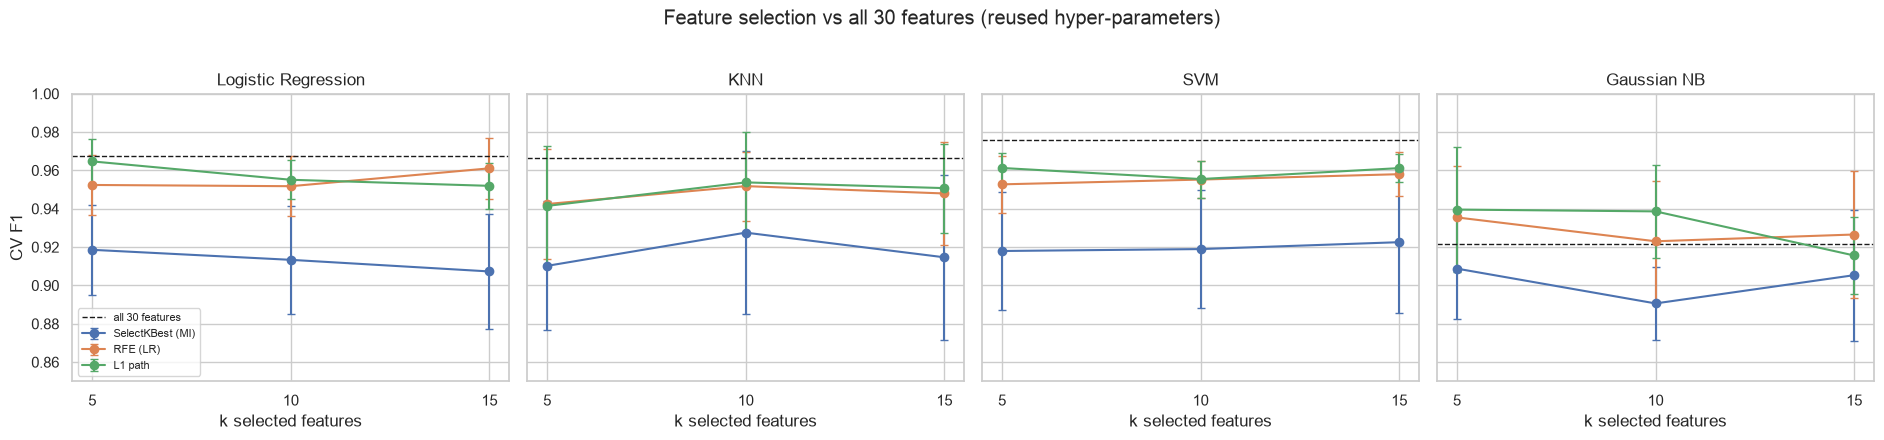

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3), sharey=True)
for ax, key in zip(axes, CLASSIFIERS):
    g = fs_df[fs_df.key == key]
    full = g[g.method == "none"]["cv_f1"].iloc[0]
    for method in METHODS:
        h = g[g.method == method]
        ax.errorbar(h["n_features"], h["cv_f1"], yerr=h["cv_f1_std"], marker="o", capsize=3, label=METHOD_NAMES[method])
    ax.axhline(full, color="k", ls="--", lw=1, label="all 30 features")
    ax.set_xticks([5, 10, 15]); ax.set_xlabel("k selected features"); ax.set_title(display_name(key))
axes[0].set_ylabel("CV F1"); axes[0].legend(fontsize=8); axes[0].set_ylim(0.85, 1.0)
fig.suptitle("Feature selection vs all 30 features (reused hyper-parameters)", y=1.02); fig.tight_layout()
savefig(fig, "06_fs_main"); plt.show()

**Findings (reused hyper-parameters).**
* **The method matters more than k.** The multivariate selectors (RFE, L1 path) are far
  better than the univariate MI filter for every classifier. Even with 15 features, MI
  is 4–6 F1 points below the full feature set for LR, KNN and SVM, because its picks are
  largely redundant copies of tumour size.
* **The L1 path with only 5 features** (`radius_worst`, `perimeter_worst`,
  `concave_points_worst`, `concave_points_mean`, `texture_worst`) gives LR an F1 of 0.965,
  within 0.003 of the 30-feature LR (0.967), with malignant recall 0.965 vs 0.959.
  Five original measurements are enough for a linear model.
* **SVM loses 1.5–2 F1 points** with 5–15 selected features (0.955–0.961 vs 0.976). KNN loses
  1–2.5 points.
* **Gaussian NB improves** with selection (L1 path k=5: F1 0.940 vs 0.921 on all 30).
  Removing redundant features *does* help NB once whole redundant groups go, not just
  perimeter and area. This revises the result of notebook 02.

## 3. Performance as a function of k

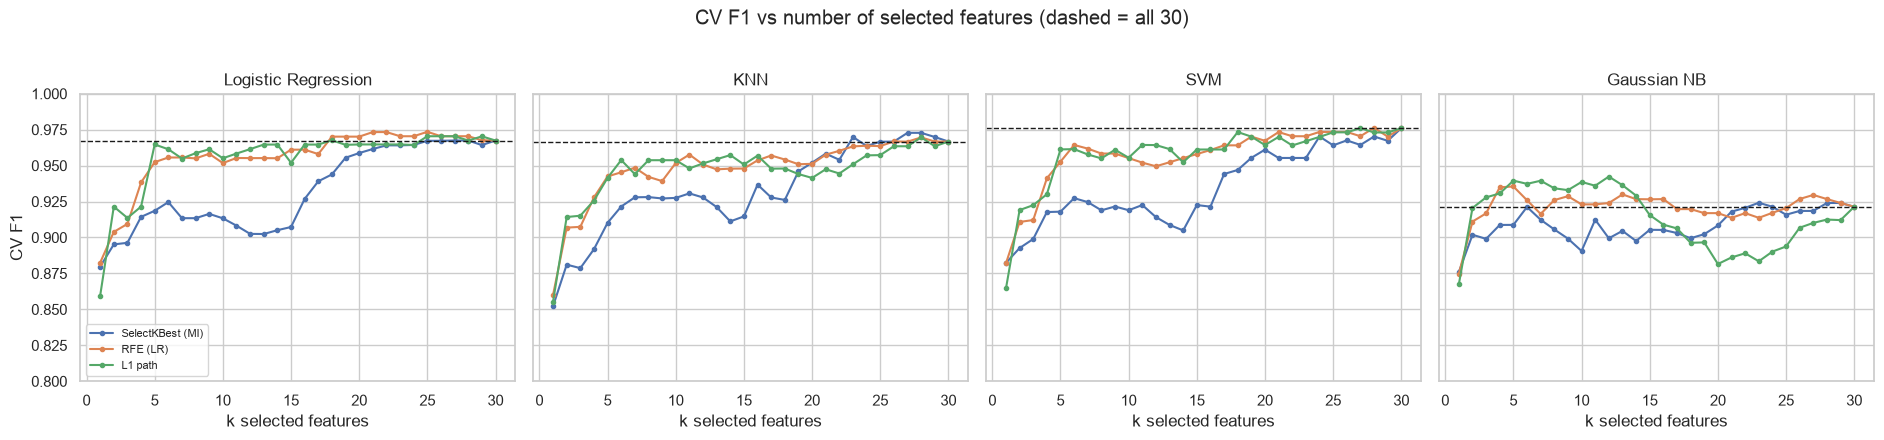

In [7]:
curve = []
for key in CLASSIFIERS:
    for method in METHODS:
        for k in range(1, 31):
            pipe = build_pipeline(key, PARAMS[key], reducer=make_selector(method, k))
            curve.append(cv_evaluate(pipe, X_train, y_train, name=display_name(key), key=key, method=method, n_features=k))
curve = pd.DataFrame(curve)
curve.to_csv(RESULTS_DIR / "cv_06_fs_curve.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.3), sharey=True)
for ax, key in zip(axes, CLASSIFIERS):
    for method in METHODS:
        h = curve[(curve.key == key) & (curve.method == method)]
        ax.plot(h["n_features"], h["cv_f1"], "o-", ms=3, label=METHOD_NAMES[method])
    ax.axhline(fs_df[(fs_df.key == key) & (fs_df.method == "none")]["cv_f1"].iloc[0], color="k", ls="--", lw=1)
    ax.set_title(display_name(key)); ax.set_xlabel("k selected features")
axes[0].set_ylabel("CV F1"); axes[0].set_ylim(0.8, 1.0); axes[0].legend(fontsize=8)
fig.suptitle("CV F1 vs number of selected features (dashed = all 30)", y=1.02); fig.tight_layout()
savefig(fig, "06_fs_curve"); plt.show()

In [8]:
small = []
for (key, method), g in curve.groupby(["key", "method"], sort=False):
    ref = fs_df[(fs_df.key == key) & (fs_df.method == "none")]["cv_f1"].iloc[0]
    ok = g[g["cv_f1"] >= ref - 0.01]
    best = g.loc[g["cv_f1"].idxmax()]
    small.append({"model": display_name(key), "method": METHOD_NAMES[method], "all30_f1": ref,
                  "best_f1": best["cv_f1"], "best_k": int(best["n_features"]),
                  "min_k_within_0.01": int(ok["n_features"].min()) if len(ok) else None})
small = pd.DataFrame(small)
small.round(4)

,model,method,all30_f1,best_f1,best_k,min_k_within_0.01
0,Logistic Regression,SelectKBest (MI),0.9674,0.9674,27,20
1,Logistic Regression,RFE (LR),0.9674,0.9735,25,9
2,Logistic Regression,L1 path,0.9674,0.9704,25,5
3,KNN,SelectKBest (MI),0.9667,0.9728,27,21
4,KNN,RFE (LR),0.9667,0.9696,28,11
5,KNN,L1 path,0.9667,0.9696,28,14
6,SVM,SelectKBest (MI),0.9760,0.9760,30,24
7,SVM,RFE (LR),0.9760,0.9763,28,19
8,SVM,L1 path,0.9760,0.9760,27,18
9,Gaussian NB,SelectKBest (MI),0.9214,0.9241,23,6


With RFE or the L1 path, LR needs only 5–9 features to get within 0.01 F1 of all 30,
and GNB 2–3 (it gets *better*). SVM needs 18–19 and KNN 11–14. The non-linear models
exploit the extra, weaker features more. MI needs 20+ features for every model except GNB.

## 4. Selection stability: are the same features chosen on every fold?
Each selector (k = 10) is fitted on each of the 5 CV training folds. A feature chosen 5/5
times is a stable choice; one that flips in and out depends on the particular sample.

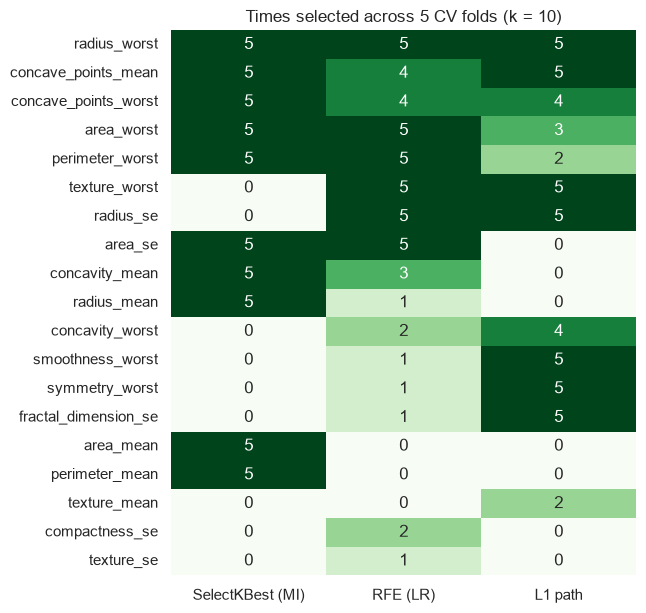

In [9]:
freq = pd.DataFrame(0, index=FEATURE_NAMES, columns=[METHOD_NAMES[m] for m in METHODS])
for tr, _ in get_cv().split(X_train, y_train):
    sc = StandardScaler().fit(X_train.iloc[tr])
    Zt = sc.transform(X_train.iloc[tr])
    for m in METHODS:
        sel = make_selector(m, 10).fit(Zt, y_train.iloc[tr])
        freq.loc[np.array(FEATURE_NAMES)[sel.get_support()], METHOD_NAMES[m]] += 1
freq["total"] = freq.sum(axis=1)
freq = freq[freq.total > 0].sort_values("total", ascending=False)
freq.to_csv(RESULTS_DIR / "fs_selection_frequency.csv")

fig, ax = plt.subplots(figsize=(6, 0.32 * len(freq) + 1))
sns.heatmap(freq.drop(columns="total"), annot=True, fmt="d", cmap="Greens", vmin=0, vmax=5, cbar=False, ax=ax)
ax.set_title("Times selected across 5 CV folds (k = 10)")
savefig(fig, "06_selection_stability"); plt.show()

In [10]:
consistent = freq[(freq.drop(columns="total") == 5).all(axis=1)].index.tolist()
print("Selected in 5/5 folds by ALL three methods:", consistent)
stable_per_method = {c: int((freq[c] == 5).sum()) for c in freq.columns[:-1]}
print("Features selected in every fold, per method:", stable_per_method)

Selected in 5/5 folds by ALL three methods: ['radius_worst']
Features selected in every fold, per method: {'SelectKBest (MI)': 10, 'RFE (LR)': 6, 'L1 path': 7}


* **MI is perfectly stable** (the same 10 features in every fold) but picks redundant features.
  Stability is not the same as usefulness.
* RFE and the L1 path are less stable, because among near-duplicates (e.g. `perimeter_worst`
  vs `radius_worst` vs `area_worst`) which one wins can flip between folds. Any of them carries
  the same information.
* **The consistently important measurements** across methods and folds are `radius_worst`,
  `concave_points_mean`, `concave_points_worst`, `area_worst` and `perimeter_worst`, followed by
  `texture_worst` and `radius_se`. This matches the tree importances of notebook 04.

## 5. L1 regularisation for classification vs L1-based feature selection
Coordination with Member 2:
* **(a) L1 as the classifier.** Member 2's best L1-penalised logistic regression learns
  sparse weights and classifies with them in one step.
* **(b) L1 as a selector.** The L1 path only chooses the features. A separately tuned
  classifier (L2 LR or RBF SVM) is then trained on them, with the same number of
  features as (a) uses.

In [11]:
l1p = PARAMS["logreg_l1"]
l1_clf = build_pipeline("logreg", l1p)
nz = int((l1_clf.fit(X_train, y_train).named_steps["clf"].coef_ != 0).sum())
print(f"L1 logistic regression (C={l1p['clf__C']:.3g}) uses {nz} non-zero features on the full training set")
cmp_rows = [cv_evaluate(l1_clf, X_train, y_train, name=f"(a) L1-penalised LR classifier (~{nz} features)")]
for key in ["logreg", "svm"]:
    pipe = build_pipeline(key, PARAMS[key], reducer=L1PathSelector(k=nz))
    cmp_rows.append(cv_evaluate(pipe, X_train, y_train, name=f"(b) L1-path select {nz} → {display_name(key)}"))
cmp_rows.append(cv_evaluate(build_pipeline("logreg", PARAMS["logreg"]), X_train, y_train, name="L2 LR, all 30 (reference)"))
save_rows(cmp_rows, "cv_06_l1_comparison.csv")
summarize(cmp_rows)

L1 logistic regression (C=0.316) uses 9 non-zero features on the full training set


,model,accuracy,precision,recall,specificity,f1,roc_auc
0,(a) L1-penalised LR classifier (~9 features),0.9736 ± 0.0054,0.9709 ± 0.0176,0.9588 ± 0.0235,0.9825 ± 0.0111,0.9644 ± 0.0075,0.9941 ± 0.0046
1,(b) L1-path select 9 → Logistic Regression,0.9714 ± 0.0054,0.9714 ± 0.0252,0.9529 ± 0.0300,0.9825 ± 0.0157,0.9613 ± 0.0076,0.9943 ± 0.0043
2,(b) L1-path select 9 → SVM,0.9714 ± 0.0054,0.9769 ± 0.0210,0.9471 ± 0.0343,0.9860 ± 0.0131,0.9610 ± 0.0082,0.9945 ± 0.0049
3,"L2 LR, all 30 (reference)",0.9758 ± 0.0082,0.9766 ± 0.0215,0.9588 ± 0.0144,0.9860 ± 0.0131,0.9674 ± 0.0109,0.9949 ± 0.0056


L1 used as the classifier and L1 used as a selector perform almost the same here
(F1 0.964 vs 0.961), and both are within ≈0.006 of the dense L2 model on all 30 features.
The one-step L1 classifier is the simpler choice. Using L1 only to pick features is useful
when a *different* downstream model is wanted, but with ~9 features the RBF SVM gains
nothing over the linear model.

## 6. Sanity check: re-tuning the classifiers on the selected features
As in notebook 05, hyper-parameters tuned on 30 features may not suit 5–15 features.
RFE and L1-path settings are re-tuned with the members' grids. MI is excluded because
re-fitting MI inside every grid candidate is expensive, and MI is clearly the weakest
selector anyway.

In [12]:
from models import GRIDS
retuned = []
for key in CLASSIFIERS:
    for method in ["RFE", "L1"]:
        for k in [5, 10, 15]:
            gs = tune(build_pipeline(key, reducer=make_selector(method, k)), GRIDS[key], X_train, y_train)
            row = best_cv_row(gs, display_name(key), key=key, method=method, n_features=k)
            row["reused_f1"] = fs_df[(fs_df.key == key) & (fs_df.method == method) & (fs_df.n_features == k)]["cv_f1"].iloc[0]
            row["best_params"] = {p.replace("clf__", ""): v for p, v in gs.best_params_.items()}
            retuned.append(row)
rt = pd.DataFrame(retuned)
rt["gain_from_retuning"] = rt["cv_f1"] - rt["reused_f1"]
rt.to_csv(RESULTS_DIR / "cv_06_fs_retuned.csv", index=False)
rt[["model", "method", "n_features", "reused_f1", "cv_f1", "gain_from_retuning", "cv_recall", "best_params"]].round(4)

,model,method,n_features,reused_f1,cv_f1,gain_from_retuning,cv_recall,best_params
0,Logistic Regression,RFE,5,0.9524,0.9563,0.0039,0.9647,"{'C': 31.622776601683793, 'class_weight': 'bal..."
1,Logistic Regression,RFE,10,0.9517,0.9549,0.0032,0.9412,"{'C': 0.1, 'class_weight': None, 'l1_ratio': 1}"
2,Logistic Regression,RFE,15,0.9611,0.9675,0.0064,0.9647,"{'C': 10.0, 'class_weight': None, 'l1_ratio': 0}"
3,Logistic Regression,L1,5,0.9647,0.9650,0.0003,0.9706,"{'C': 1.0, 'class_weight': 'balanced', 'l1_rat..."
4,Logistic Regression,L1,10,0.9551,0.9703,0.0152,0.9647,"{'C': 3.1622776601683795, 'class_weight': 'bal..."
5,Logistic Regression,L1,15,0.9519,0.9675,0.0156,0.9647,"{'C': 1.0, 'class_weight': 'balanced', 'l1_rat..."
6,KNN,RFE,5,0.9425,0.9545,0.0120,0.9353,"{'n_neighbors': 5, 'p': 1, 'weights': 'uniform'}"
7,KNN,RFE,10,0.9518,0.9518,0.0000,0.9353,"{'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}"
8,KNN,RFE,15,0.9480,0.9536,0.0057,0.9235,"{'n_neighbors': 7, 'p': 1, 'weights': 'uniform'}"
9,KNN,L1,5,0.9415,0.9545,0.0130,0.9353,"{'n_neighbors': 9, 'p': 2, 'weights': 'uniform'}"


**Re-tuning matters more here than for PCA.** It recovers 1–1.5 F1 points for several
configurations. With 10 L1-path features, LR reaches CV F1 0.970 and a (now linear) SVM
0.971, essentially equal to the 30-feature models (0.967 / 0.976). Part of the gap seen
with reused parameters therefore came from hyper-parameters tuned for 30 dimensions (e.g.
the RBF `gamma`), not from lost information. The ranking of methods is unchanged:
L1 path ≥ RFE ≫ MI.

## Summary
* **Univariate filtering (MI) is the wrong tool** for strongly correlated features. It
  selects many copies of "tumour size" and never matches the full feature set at k ≤ 15.
* **Multivariate selection works.** The L1 path with 5 features is enough for logistic
  regression (CV F1 0.965 vs 0.967), and with re-tuning, 10 selected features reach ≈0.97
  for LR and SVM.
* **Consistently important measurements:** `radius_worst`, `perimeter_worst`,
  `area_worst`, `concave_points_worst`, `concave_points_mean`, then `texture_worst` and
  `radius_se`.
* Unlike PCA, the result is a short list of *named, measurable* features, so a model on
  5–10 of them is both cheaper to apply and easier to explain.